In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import dispatch
import matplotlib
matplotlib.rcParams["figure.figsize"] = [10., 8.]
matplotlib.rcParams["figure.dpi"] = 300.
matplotlib.rcParams["font.size"] = 28.

In [9]:
colors = ["C0", "C1", "C2", "C4"]

In [10]:
def calcAngle(llcNat, llcCart, phi, size):
    ulcNat = [0., 0.]
    ulcNat[0] = llcNat[0]+size[0]
    ulcNat[1] = (ulcNat[0]*phi - 0.5*size[1]) / ulcNat[0]       
    ulcCart = [ulcNat[0]*np.cos(ulcNat[1]),
        ulcNat[0]*np.sin(ulcNat[1])]
    angle = np.arctan2((ulcCart[1]-llcCart[1]),
        (ulcCart[0]-llcCart[0]))
    return np.rad2deg(angle)

In [11]:
def drawPatch(patch, i):
    llcNat = patch.llc_nat[0:2]
    #llcCart = tuple([llcNat[0]*np.cos(llcNat[1]),
    #    llcNat[0]*np.sin(llcNat[1])])
    llcCart = patch.llc_cart[0:2]
    angle = calcAngle(llcNat, llcCart, patch.centre_nat[1],
        patch.size)
    width, height = [size for size in patch.size[0:2]]
    axes.add_patch(patches.Rectangle(llcCart, width, height,
        angle = angle, color = colors[i%3], fill = False))    

In [12]:
def drawCells(patch, i):
    llcNat = patch.llc_nat[0:2]
    #llcCart = tuple([llcNat[0]*np.cos(llcNat[1]),
    #    llcNat[0]*np.sin(llcNat[1])])
    llcCart = patch.llc_cart[0:2]
    for j in range(patch.n[0]):
        for k in range(patch.n[1]):
            llc = [llcCart[0] + j*patch.ds[0],
                llcCart[1] + k*patch.ds[1]]
            width, height = [size for size in patch.ds[0:2]]
            axes.add_patch(patches.Rectangle(llc, width, height,
                color = colors[i%3], fill = False))    

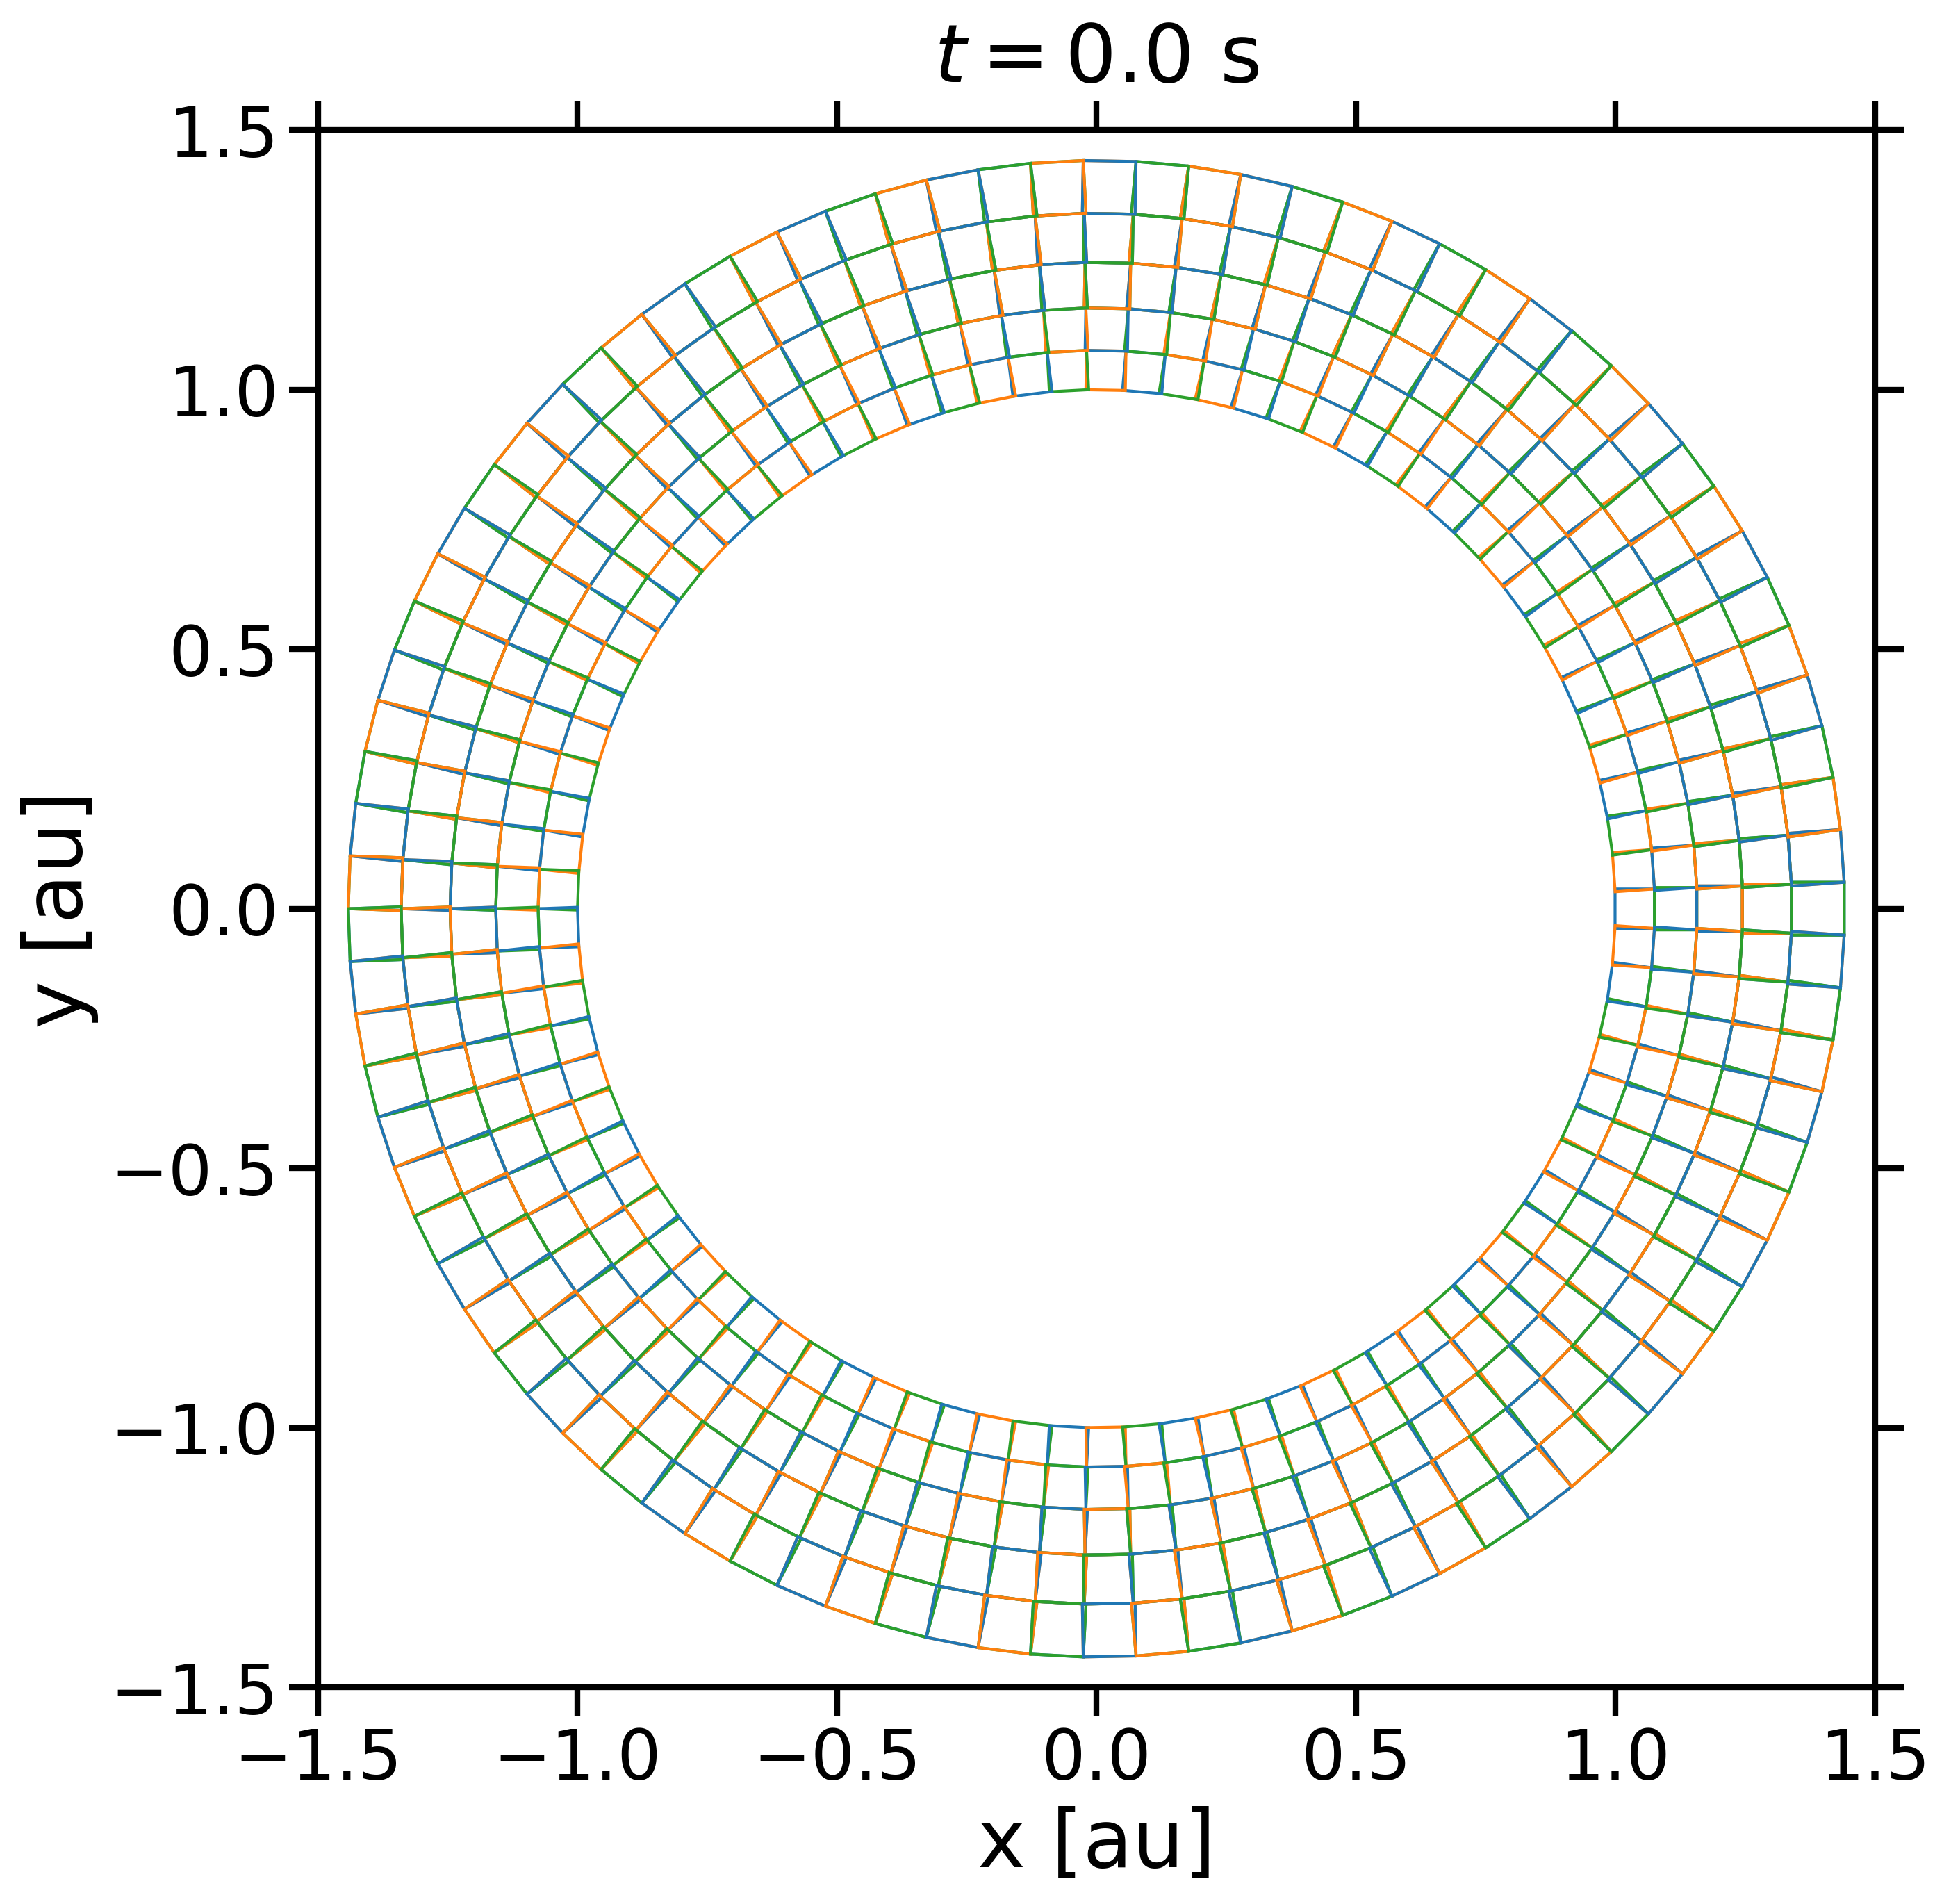

In [13]:
figure = plt.figure(figsize = (10., 10.))
axes = figure.add_subplot(111, aspect = "equal")

snap = dispatch.snapshot(iout = 0, data = "../data")

for i, patch in enumerate(snap.patches):
    drawPatch(patch, i)
    
axes.set_xlim(-1.5, 1.5)
axes.set_xlabel("x [au]")
axes.set_ylim(-1.5, 1.5)
axes.set_ylabel("y [au]")
axes.set_title(r"$t=$%.1f s" % snap.dict["time"], y = 1.02)
plt.tick_params(top = True, right = True, which = "both")
figure.savefig("geometry_radial-azimuthal_plane")

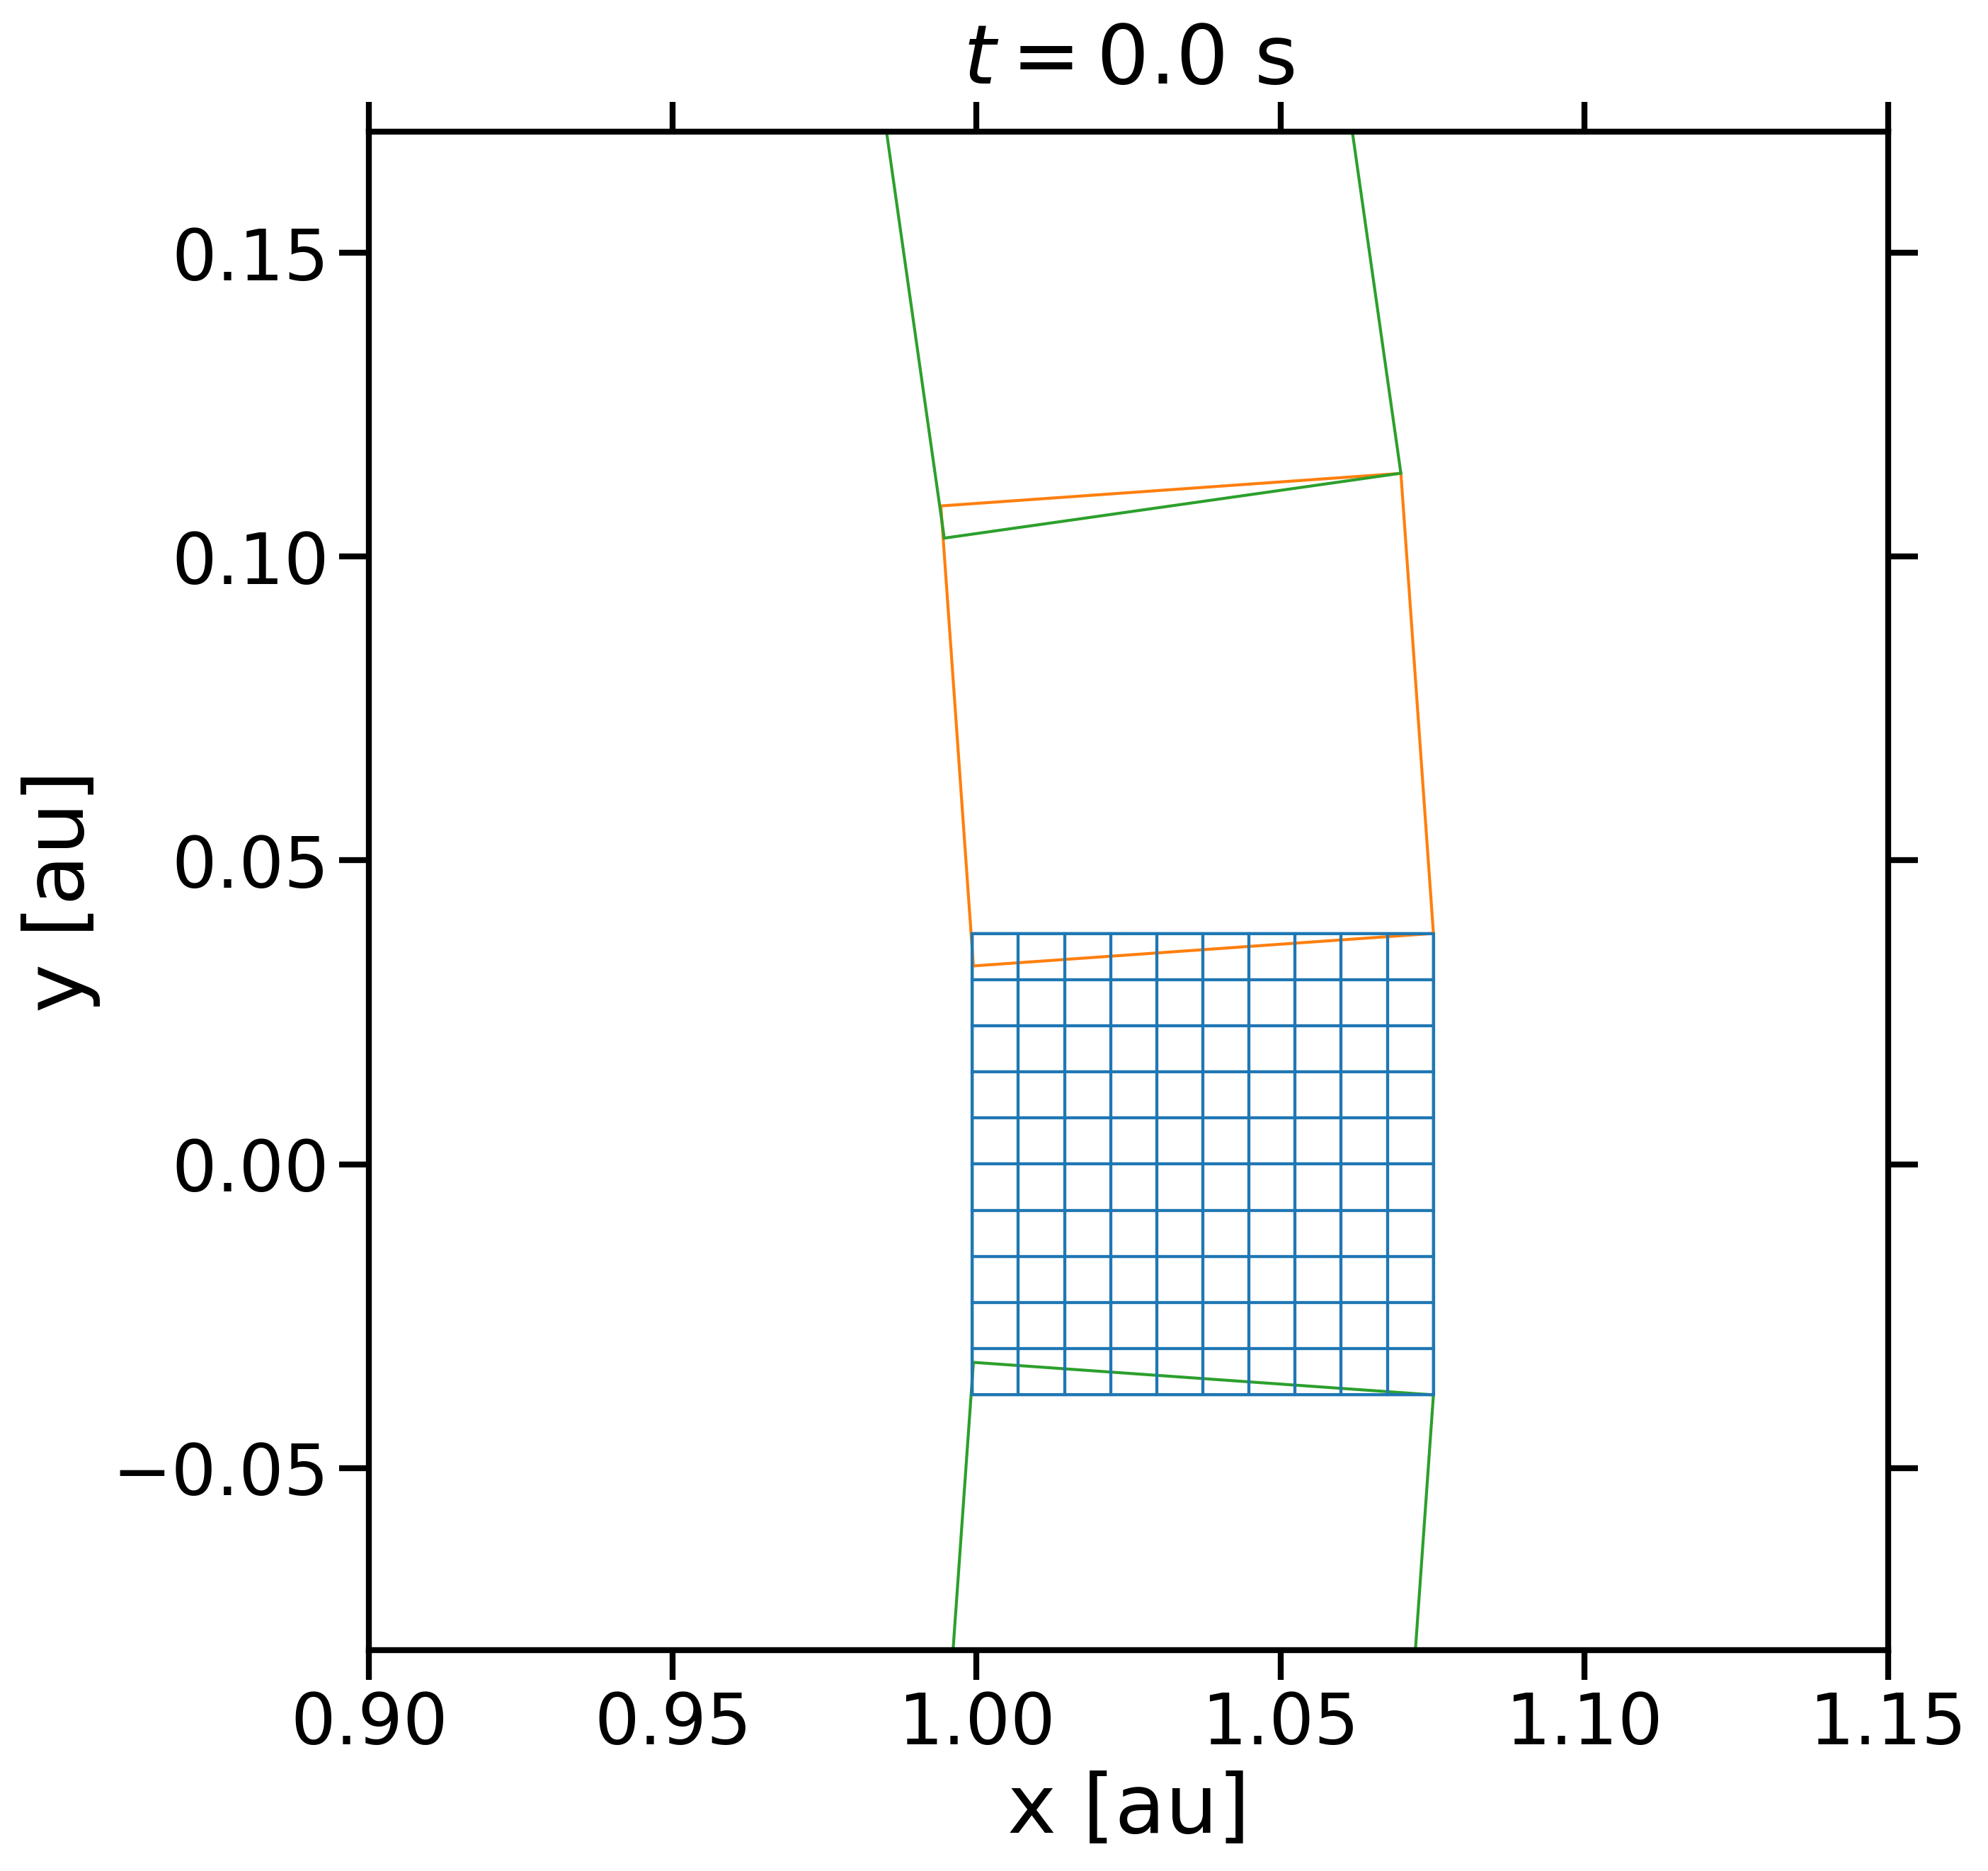

In [14]:
figure = plt.figure(figsize = (10., 10.))
axes = figure.add_subplot(111, aspect = "equal")

snap = dispatch.snapshot(iout = 0, data = "../data")

for i, patch in enumerate(snap.patches[0:3]):
    drawPatch(patch, i)
drawPatch(snap.patches[88], 2)
drawCells(snap.patches[0], 0)
    
axes.set_xlim(0.9, 1.15)
axes.set_xlabel("x [au]")
axes.set_ylim(-0.08, 0.17)
axes.set_ylabel("y [au]")
axes.set_title(r"$t=$%.1f s" % snap.dict["time"], y = 1.02)
plt.tick_params(top = True, right = True, which = "both")
figure.savefig("geometry_radial-azimuthal_plane_zoom-in")